# 04 · EMT-TF Expression (unconditional; last notebook, non-branching path)

Categorical overlay of thresholded EMT-TF **expressers** on a grey manifold. Panel gated on detectable
expression; the candidate panel spans Snail/Zeb/Twist **and** the FOXC/PRRX mesenchymal families (VIM is a
mesenchymal marker, not a TF, and is excluded). We classify each detected TF by its pseudotime end and
report the honest direction — we do **not** force an early/late pair if the data do not support one.

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load signatures manifold; house linear layout

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 633 | pseudotime range 0.0 -> 9.05


### Score the EMT-TF panel — detection-gated, honest direction
Score each candidate TF by fraction expressing and mean expression in the early (root) vs late (terminus)
pseudotime terciles; keep factors detected in >3% of cells. Report each TF end honestly: here EMT-TF
expression is sparse and **all detected TFs are origin/root-enriched** (mean_early > mean_late, rho<=0),
with no factor marking the neural-crest terminus — so we overlay the two most-expressed origin factors
rather than fabricate an early<->late dichotomy.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03].copy()
n_early = int((ok.end=='EARLY(root)').sum()); n_late = int((ok.end=='LATE(terminus)').sum())
print(f'\ndetected (>3%) EMT-TFs: {ok.TF.tolist()} | EARLY(root)={n_early} LATE(terminus)={n_late}')
if n_early == len(ok):
    direction = 'all origin/root-enriched (no terminal EMT-TF; EMT-TF programme sits at the Gast/pSom origin)'
elif n_late == len(ok):
    direction = 'all terminus-enriched'
else:
    direction = 'mixed early/late'
print('EMT-TF direction:', direction)
# overlay the two most-expressed detected TFs (honest labels by their own end classification)
show = ok.sort_values('frac_expr', ascending=False).head(2)['TF'].tolist()
ends = {r.TF: ('origin' if r.end=='EARLY(root)' else 'terminus') for r in ok.itertuples()}
print('overlay TFs (two most-expressed):', {g: ends[g] for g in show})

   TF  frac_expr  mean_early  mean_late  rho_vs_t         end
SNAI1      0.084       0.050      0.026    -0.042 EARLY(root)
FOXC1      0.068       0.042      0.026    -0.094 EARLY(root)
PRRX2      0.035       0.019      0.017    -0.001 EARLY(root)

detected (>3%) EMT-TFs: ['SNAI1', 'FOXC1', 'PRRX2'] | EARLY(root)=3 LATE(terminus)=0
EMT-TF direction: all origin/root-enriched (no terminal EMT-TF; EMT-TF programme sits at the Gast/pSom origin)
overlay TFs (two most-expressed): {'SNAI1': 'origin', 'FOXC1': 'origin'}


### Deliverable — `expression.pdf` (categorical overlay of thresholded expressers)
Grey manifold; the two most-expressed detected EMT-TFs overlaid as thresholded expressers, each labelled
by its own pseudotime end. Both are origin-enriched here — the honest readout.

overlay thresholds (upper quartile among expressers): {'SNAI1': 0.781, 'FOXC1': 0.77} | cells shown: {'SNAI1': 13, 'FOXC1': 11}
SNAI1: 8.4% expressing; 13 shown (upper quartile), mean pseudotime of shown = 0.53 (all = 0.56); end=origin
FOXC1: 6.8% expressing; 11 shown (upper quartile), mean pseudotime of shown = 0.53 (all = 0.56); end=origin
saved expression.pdf | EMT-TF programme is origin/root-enriched (no terminal EMT-TF)


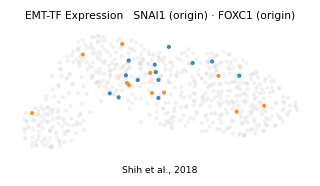

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in show:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in show}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in show},
      '| cells shown:', {g: int(sel[g].sum()) for g in show})
order = sorted(show, key=lambda g: -int(sel[g].sum()))
palette = ['tab:blue','tab:orange']
colors = {g: palette[i] for i,g in enumerate(show)}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = ' · '.join(f'{g} ({ends[g]})' for g in show)
ax.set_title(f'EMT-TF Expression   {lbl}', size=7.0)
ax.text(.5,-.14,'Shih et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in show:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f (all = %.2f); end=%s'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean(), ends[g]))
print('saved expression.pdf | EMT-TF programme is origin/root-enriched (no terminal EMT-TF)')